# Asteroid catalogue: measured sizes and orbital groups

This project asks how asteroid properties vary across the uploaded catalogue, with special attention to missing diameter measurements. The included CSV retains every source row and 15 original columns needed for this analysis; it is a column selection, not a random sample. Names, flags and orbital measurements retain their supplied values.

## Data and scope

Source: [asteroid-dataset](https://www.kaggle.com/datasets/sakhawat18/asteroid-dataset). This report uses the uploaded snapshot, not live data.

`id` is the object identifier; `full_name` is its supplied name; `class` is the orbital class code. `neo` and `pha` are supplied Y/N near-Earth-object and potentially-hazardous-asteroid flags. `H` is absolute magnitude, `diameter` is diameter in kilometres and `albedo` is reflectivity. `a` is semimajor axis in astronomical units, `e` eccentricity, `i` inclination in degrees, `q` perihelion distance in astronomical units, `per_y` orbital period in years, `moid` minimum orbit-intersection distance in astronomical units, and `rms` the supplied orbit-fit residual measure. Flags are catalogue classifications, not predictions of an impact.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def data_path(filename):
    # Works after extracting this ZIP, or after attaching its data on Kaggle.
    for folder in (Path("data"), Path(".")):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    kaggle = Path("/kaggle/input")
    matches = sorted(kaggle.rglob(filename)) if kaggle.exists() else []
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Place {filename} in data/, or attach its dataset on Kaggle. Found {len(matches)} Kaggle matches.")

In [2]:
raw = pd.read_csv(data_path("asteroid_columns.csv"),low_memory=False)
print(f"Catalogue rows: {len(raw):,}; selected original columns: {raw.shape[1]}")
assert len(raw)>=150 and raw.shape[1]>=3
display(raw.head()); display(raw.isna().sum().to_frame("missing"))

Catalogue rows: 958,524; selected original columns: 15


,id,full_name,neo,pha,H,diameter,albedo,e,a,q,i,per_y,moid,class,rms
0,a0000001,1 Ceres,N,N,3.400,939.400,0.090,0.076,2.769,2.559,10.594,4.608,1.595,MBA,0.433
1,a0000002,2 Pallas,N,N,4.200,545.000,0.101,0.230,2.774,2.136,34.833,4.620,1.234,MBA,0.359
2,a0000003,3 Juno,N,N,5.330,246.596,0.214,0.257,2.668,1.983,12.991,4.359,1.034,MBA,0.338
3,a0000004,4 Vesta,N,N,3.000,525.400,0.423,0.089,2.361,2.152,7.142,3.629,1.139,MBA,0.400
4,a0000005,5 Astraea,N,N,6.900,106.699,0.274,0.191,2.574,2.083,5.367,4.130,1.096,MBA,0.522


,missing
id,0
full_name,0
neo,4
pha,19921
H,6263
diameter,822315
albedo,823421
e,0
a,0
q,0


Duplicate IDs: 0; albedo estimates above one retained: 0


,count,mean,std,min,25%,50%,75%,max
H,"952,261.000",16.906,1.790,-1.100,16.100,16.900,17.714,33.200
diameter,"136,209.000",5.506,9.425,0.003,2.780,3.972,5.765,939.400
albedo,"135,103.000",0.131,0.110,0.001,0.053,0.079,0.190,1.000
a,"958,520.000",2.925,35.958,0.555,2.388,2.647,3.002,"33,488.896"
e,"958,524.000",0.156,0.093,0.000,0.092,0.145,0.201,1.855
i,"958,524.000",9.055,6.638,0.008,4.165,7.416,12.408,175.083
q,"958,524.000",2.395,2.139,0.071,1.971,2.226,2.578,80.399
per_y,"958,520.000",13.923,"6,321.591",0.414,3.690,4.307,5.201,"6,128,574.185"
moid,"938,603.000",1.415,2.157,0.000,0.980,1.241,1.593,79.477
rms,"958,522.000",0.561,2.746,0.000,0.518,0.566,0.614,"2,686.600"


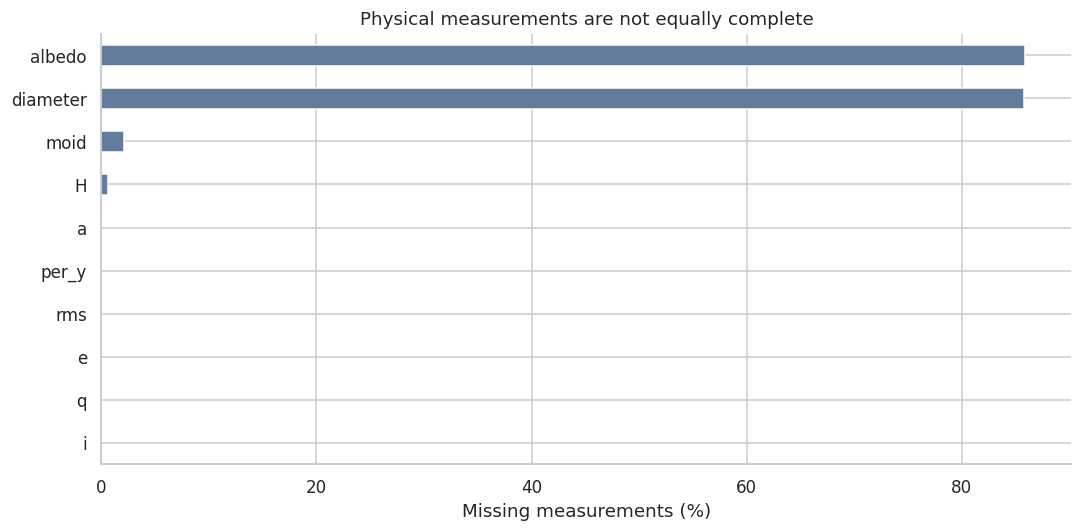

In [3]:
df = raw.drop_duplicates().copy()
for col in ["neo","pha","class"]:
    df[col] = df[col].astype("string").str.strip()
numeric = ["H","diameter","albedo","a","e","i","q","per_y","moid","rms"]
for col in numeric:
    df[col] = pd.to_numeric(df[col],errors="coerce")
for col in ["diameter","a","per_y"]:
    df.loc[df[col]<=0,col] = np.nan
for col in ["albedo","e","i","q","moid","rms"]:
    df.loc[df[col]<0,col] = np.nan
df.loc[df.i>180,"i"] = np.nan
for flag in ["neo","pha"]:
    df.loc[~df[flag].isin(["Y","N"]),flag] = pd.NA
print(f"Duplicate IDs: {df.id.duplicated().sum():,}; albedo estimates above one retained: {df.albedo.gt(1).sum():,}")
display(df[numeric].describe().T)
missing = df[numeric].isna().mean().mul(100).sort_values()
missing.plot.barh(color="#647b9b")
plt.xlabel("Missing measurements (%)"); plt.title("Physical measurements are not equally complete")
plt.tight_layout(); plt.show()

## 1. Which orbital classes are most common in the catalogue?

`value_counts()` counts the supplied orbital class codes, including unclassified objects in a separate label. Full counts are shown, while the chart displays the ten largest groups. This is a catalogue composition, not an unbiased estimate of all asteroids in space.

,objects,share_pct
class,,
MBA,855954,89.299
OMB,28355,2.958
IMB,20360,2.124
MCA,18685,1.949
APO,12687,1.324
AMO,8457,0.882
TJN,8221,0.858
TNO,3468,0.362
ATE,1729,0.180


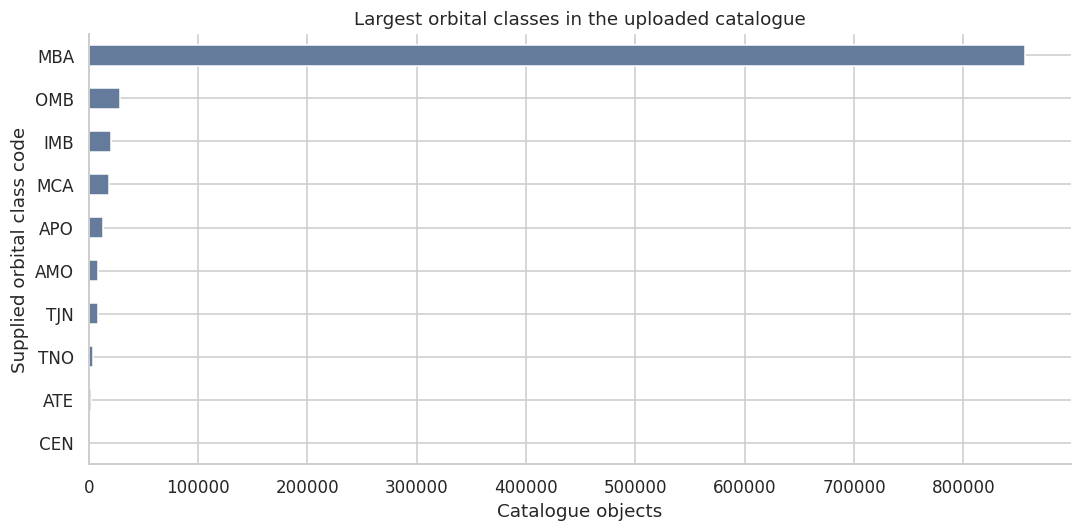

In [4]:
classes = df["class"].fillna("Unknown").value_counts()
display(pd.DataFrame({"objects":classes,"share_pct":classes/len(df)*100}))
classes.head(10).sort_values().plot.barh(color="#647b9b")
plt.xlabel("Catalogue objects"); plt.ylabel("Supplied orbital class code")
plt.title("Largest orbital classes in the uploaded catalogue"); plt.tight_layout(); plt.show()

**Answer.** Class MBA is the largest group, with 855,954 objects (89.3% of the catalogue). Detection and classification practices affect these proportions.

## 2. What does the measured-diameter distribution look like?

Only positive reported diameters are used. A logarithmic horizontal axis is appropriate because sizes span several orders of magnitude. `quantile()` reports the middle and tails without allowing the largest object to dominate the summary.

Measured diameters: 136,209 of 958,524 objects (14.21%)


,diameter_km
0.000,0.003
0.100,2.029
0.250,2.780
0.500,3.972
0.750,5.765
0.900,8.643
1.000,939.400


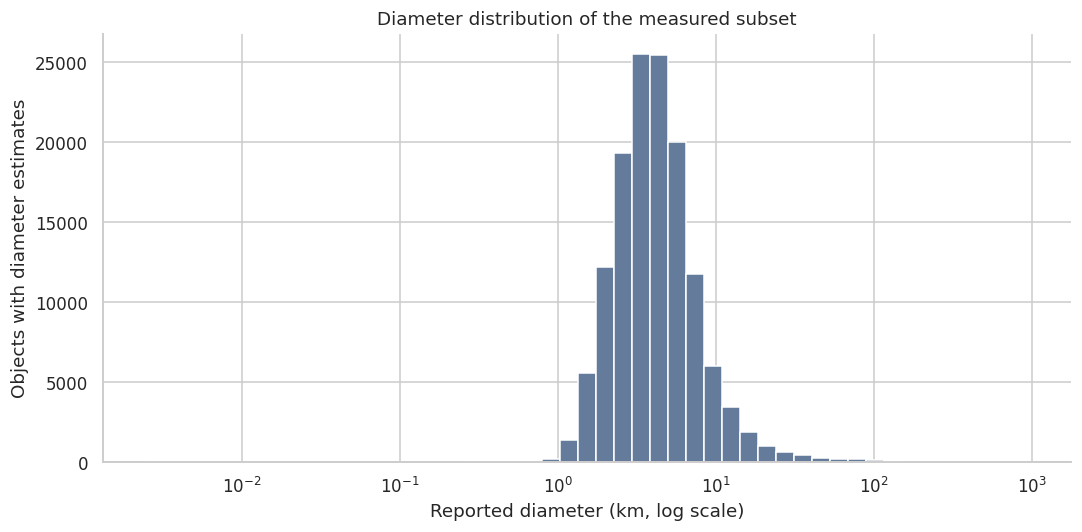

In [5]:
measured = df.dropna(subset=["diameter"])
display(measured.diameter.quantile([0,.1,.25,.5,.75,.9,1]).to_frame("diameter_km"))
print(f"Measured diameters: {len(measured):,} of {len(df):,} objects ({len(measured)/len(df)*100:.2f}%)")
plt.hist(measured.diameter,bins=np.geomspace(measured.diameter.min(),measured.diameter.max()*1.001,50),color="#647b9b")
plt.xscale("log"); plt.xlabel("Reported diameter (km, log scale)"); plt.ylabel("Objects with diameter estimates")
plt.title("Diameter distribution of the measured subset"); plt.tight_layout(); plt.show()

**Answer.** The measured subset has a median diameter of 3.972 km; its 10th and 90th percentiles are 2.029 and 8.643 km. Diameter is present for only 14.2% of catalogue rows, so these statistics should not be presented as the size distribution of the whole population.

## 3. How common are the supplied near-Earth and potentially hazardous flags?

`crosstab()` counts each pair of flags, including unknown values. Diameter availability is also compared across near-Earth groups. Different completeness rates are a warning against comparing measured sizes as though objects were sampled uniformly.

pha,N,Unknown,Y
neo,,,
N,915705,19920,0
Unknown,4,0,0
Y,20828,1,2066


,count,diameter_available_pct
neo,,
N,935625,14.467
Y,22895,3.708
<NA>,4,0.000


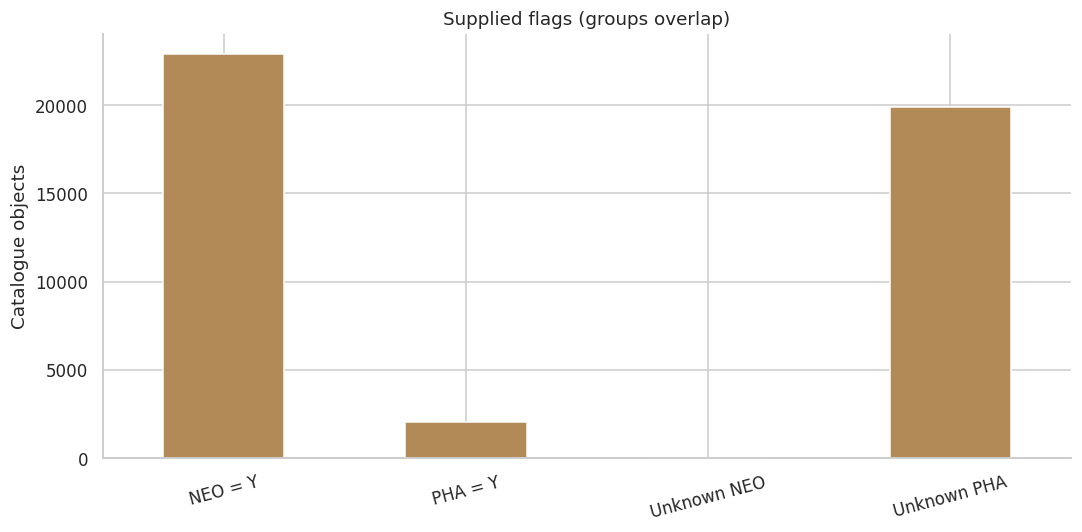

In [6]:
flags = pd.crosstab(df.neo.fillna("Unknown"),df.pha.fillna("Unknown"))
display(flags)
diameter_coverage = df.assign(has_diameter=df.diameter.notna()).groupby("neo",dropna=False).has_diameter.agg(["count","mean"])
diameter_coverage["diameter_available_pct"] = diameter_coverage["mean"]*100
display(diameter_coverage[["count","diameter_available_pct"]])
flag_counts = pd.Series({"NEO = Y":df.neo.eq("Y").sum(),"PHA = Y":df.pha.eq("Y").sum(),"Unknown NEO":df.neo.isna().sum(),"Unknown PHA":df.pha.isna().sum()})
flag_counts.plot.bar(color="#b18a58",rot=15)
plt.ylabel("Catalogue objects"); plt.title("Supplied flags (groups overlap)"); plt.tight_layout(); plt.show()

**Answer.** The catalogue labels 22,895 objects as near-Earth and 2,066 as potentially hazardous. These groups overlap. A PHA label identifies an orbital/size screening category; it is not a statement that an impact is expected.

## 4. How do orbital eccentricities differ between large classes?

The five most common known class codes are compared. `boxplot(showfliers=False)` hides extreme markers only in the drawing; all valid observations still contribute to the box statistics and the table. Eccentricity describes orbit shape, not collision probability.

,count,median,mean,min,max
class,,,,,
APO,12687,0.501,0.487,0.008,0.970
IMB,20360,0.076,0.076,0.001,0.164
MBA,855954,0.145,0.148,0.000,0.474
MCA,18685,0.303,0.298,0.000,0.590
OMB,28355,0.126,0.143,0.000,0.693


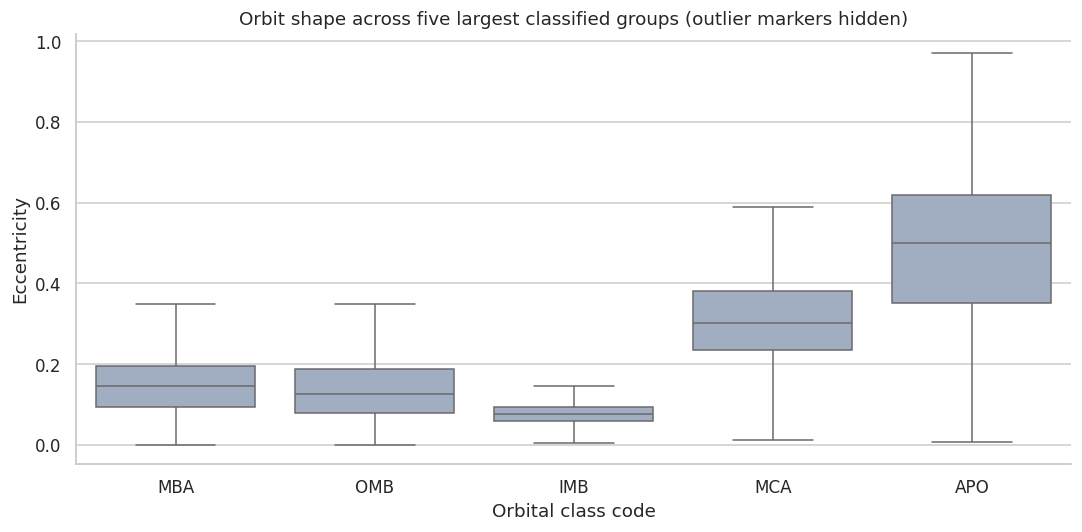

In [7]:
main_classes = df["class"].value_counts().head(5).index
orbit = df[df["class"].isin(main_classes)].dropna(subset=["e"])
eccentricity = orbit.groupby("class").e.agg(["count","median","mean","min","max"])
display(eccentricity)
sns.boxplot(data=orbit,x="class",y="e",order=main_classes,showfliers=False,color="#9cadc7")
plt.xlabel("Orbital class code"); plt.ylabel("Eccentricity")
plt.title("Orbit shape across five largest classified groups (outlier markers hidden)"); plt.tight_layout(); plt.show()

**Answer.** Among these five groups, APO has the highest median eccentricity (0.501). Classes are defined using orbital properties, so differences between them are partly expected from how the groups are constructed.

## 5. How is absolute magnitude related to reported diameter?

Objects with both measurements are used for the table and rank correlation. `sample(random_state=...)` draws a reproducible display sample of at most 8,000 objects. The full subset is used for the calculation. Reflectivity is an additional physical influence, so magnitude alone does not uniquely determine size.

,count,mean,std,min,25%,50%,75%,max
H,"132,045.000",15.132,1.388,3.000,14.400,15.200,16.000,29.900
diameter,"132,045.000",5.603,9.556,0.003,2.848,4.051,5.847,939.400
albedo,"131,237.000",0.132,0.111,0.001,0.053,0.079,0.195,1.000


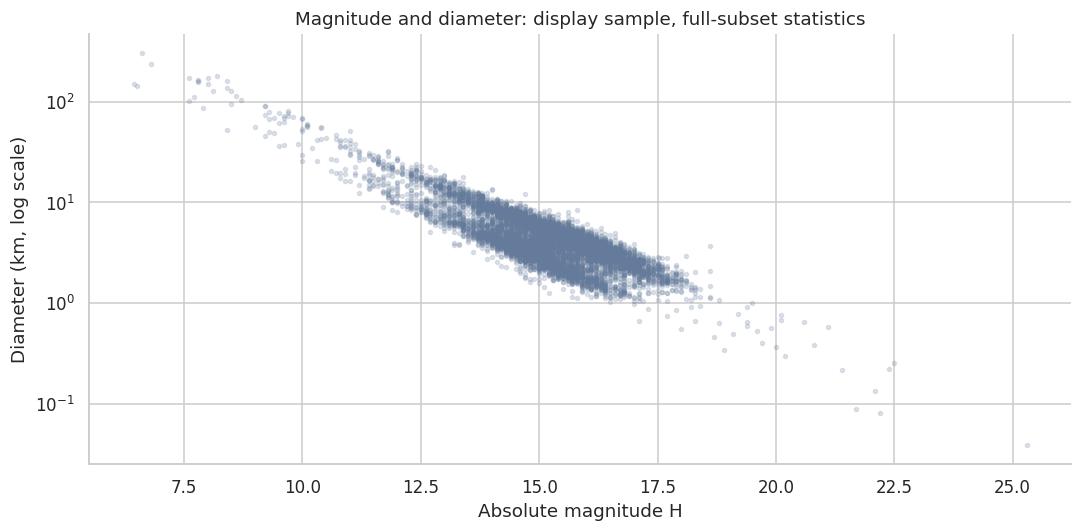

In [8]:
paired = df.dropna(subset=["H","diameter"])
rho = paired.H.corr(paired.diameter,method="spearman")
display(paired[["H","diameter","albedo"]].describe().T)
sample = paired.sample(min(8000,len(paired)),random_state=23)
plt.scatter(sample.H,sample.diameter,s=7,alpha=.2,color="#647b9b")
plt.yscale("log"); plt.xlabel("Absolute magnitude H"); plt.ylabel("Diameter (km, log scale)")
plt.title("Magnitude and diameter: display sample, full-subset statistics")
plt.tight_layout(); plt.show()

**Answer.** Across 132,045 objects with both fields, the Spearman correlation is -0.737. Larger H values tend to accompany smaller reported diameters in this measured subset. Missing measurements and differences in albedo limit any simple one-variable size estimate.

## Conclusion

The MBA class accounts for 89.3% of catalogue objects. Only 14.2% of rows have a reported diameter; the median diameter within that measured subset is 3.972 km. Measurement completeness is therefore central to interpreting the results.

The catalogue is dominated by a small number of orbital classes, but physical measurements are much less complete than the object list. Diameter summaries therefore describe a measured subset. The supplied flags and orbital group differences are useful for describing the catalogue, with no impact forecast inferred.
